# Tutorial 01 — Zero-Download Playground: Exploring 8 Intracortical BCI Reproductions in 3 Minutes
*Language: **English** | [中文版 (Chinese Version)](zh/01_zero_download_results_playground_zh.ipynb)*

Welcome to **`communication-neuroprostheses-reproduction`**!
Downloading 100+ GB of raw intracortical neural recordings (`.mat` / `.hdf5`) from Dryad can take hours. So that you can **start exploring immediately with zero external downloads**, every study directory archives our single-GPU per-trial decode outputs, phoneme error rates (PER), character error rates (CER), and word error rates (WER) under `yyyymmdd_author/results/`.

In this notebook, you will run four hands-on experiments:
1. **Benchmark Panorama**: Load `figures/reproduction_benchmark.yaml` and inspect all 8 *Nature* / *NEJM* / *Cell* / *NeurIPS* studies across modalities, vocabulary sizes, consumer-PC memory peaks, and reproduction accuracy.
2. **Stage-by-Stage Speech Decoding Anatomy (Willett 2023 & Card 2024)**: Trace how the exact same neural trial progresses from **Greedy CTC Phonemes → 1.46 GB KenLM 3-gram → 125k 5-gram WFST → OPT-6.7B → Qwen3-8B** and see how homophones and phoneme substitutions get repaired.
3. **The Language-Model Phase Transition (`PER` vs. `Post-LM WER`)**: Reconstruct Panel (i) of the benchmark figure to see why language models reduce errors when $\text{PER} < 26\%$ but trigger hallucinated word insertions when $\text{PER} > 30\%$.
4. **403-Day Neural Drift vs. Unsupervised CORP Recalibration (Fan 2023)**: Visualize a full year of intracortical recording drift on participant T5 and see how online pseudo-label adaptation restores character error rate to $6.20\%$.

In [1]:
from pathlib import Path
import csv
import json
import re
import yaml
import editdistance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate repository root whether launched from repo root, tutorials/, or tutorials/zh/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "figures" / "reproduction_benchmark.yaml").exists())
print(f"Repository root: {REPO_ROOT}")

with open(REPO_ROOT / "figures" / "reproduction_benchmark.yaml", encoding="utf-8") as f:
    bench = yaml.safe_load(f)

print("Hardware baseline:", bench["hardware_spec"])

Repository root: D:\repositories\20261106_communication_neuroprostheses_reproduction
Hardware baseline: {'gpu': '1x NVIDIA RTX 5060 Ti (16 GB VRAM)', 'host_ram_gb': 64.0, 'gpu_vram_gb': 16.0}


## 1. Benchmark Panorama: Reproduction Summary Across All 8 Studies

Let's extract the acoustic/character stage metrics (Panel e) and full-pipeline word error rates (Panel f) from `figures/reproduction_benchmark.yaml` into a clean DataFrame.

In [2]:
summary_rows = []
for ac, wf in zip(bench["panel_e_repro_acoustic"], bench["panel_f_repro_full_wer"]):
    label_clean = ac["label"].replace("\n", " ")
    summary_rows.append({
        "Study & Participant": label_clean,
        "Acoustic (Ours %)": ac["ours"],
        "Acoustic (Paper %)": ac["paper"],
        "Full-Pipeline WER (Ours %)": wf["ours"],
        "Full-Pipeline WER (Paper %)": wf["paper"],
        "Note": wf["note"].replace("\n", " ") if wf["note"] else (ac["note"] or ""),
    })

summary_table = pd.DataFrame(summary_rows)
print(summary_table.to_string(index=False))

                 Study & Participant  Acoustic (Ours %)  Acoustic (Paper %)  Full-Pipeline WER (Ours %)  Full-Pipeline WER (Paper %)                                   Note
           Willett et al., 2021 (T5)               4.71                2.78                       10.00                         3.64                     bigram 63-tr. pool
          Willett et al., 2023 (T12)              23.42               19.70                       23.58                        23.80                        day med. 5-gram
Fan et al., 2023 (T5, held-out CORP)              12.39                6.35                         NaN                         6.16 Full-pipeline reproduction unavailable
             Card et al., 2024 (T15)              10.31                9.54                        6.25                         6.70                    41-s pool biGRU-48k
        Wairagkar et al., 2025 (T15)              31.40               17.00                         NaN                          NaN        

## 2. Stage-by-Stage Speech Decoding Anatomy: From Phoneme Posteriors to LLM Rescoring

In **Willett et al. (*Nature* 2023, T12)** and **Card et al. (*NEJM* 2024, T15)**, neural decoding operates in three sequential stages:
1. **Acoustic Stage (5-layer GRU + CTC Loss)**: Maps 20 ms bins of neural spike-band power and threshold crossings into frame-level posteriors over 39 ARPAbet phonemes + word-boundary silence (`SIL`) + CTC `<blank>`.
2. **First-Pass Language Model Decoding (WFST Beam Search)**: Constrains the noisy phoneme stream to a 125,000-word pronunciation lexicon weighted by an n-gram language model to emit an N-best lattice of word hypotheses.
3. **Second-Pass LLM Rescoring (OPT-6.7B / Qwen3-8B)**: Scores each candidate sentence with a causal autoregressive LLM and selects the hypothesis maximizing $\text{score} = s_{\text{WFST}} + \alpha \cdot \log P_{\text{LLM}}(w) + \beta \cdot |w|$.

Below, we load the archived per-trial decode files from `studies/20230831_willett/results/20261124_import_btot24/`, recompute pooled WER using the official tokenization convention (`shared/tools/wer_from_tsv.py`), and inspect individual trials across decoding tiers.

In [3]:
import sys
sys.path.insert(0, str(REPO_ROOT / 'figures' / 'code'))
from build_session_per_vs_wer import read_tsv

def norm_tokens(sent: str) -> list[str]:
    """Official sidecar tokenization (matches shared/tools/wer_from_tsv.py)."""
    return re.sub(r"[^A-Za-z'< ]", " ", sent).upper().split()

def compute_official_wer(pairs: list[tuple[str, str]]) -> float:
    tot_ed, tot_ref = 0, 0
    for ref, hyp in pairs:
        r_tok = norm_tokens(ref)
        h_tok = norm_tokens(hyp)
        tot_ed += editdistance.eval(r_tok, h_tok)
        tot_ref += len(r_tok)
    return 100.0 * tot_ed / max(1, tot_ref)

willett_dir = REPO_ROOT / "studies/20230831_willett/results/20261124_import_btot24"

with open(willett_dir / "word_decode_joint3gram.csv", encoding="utf-8") as f:
    rows_3g = [(r["sentence_label"], r["hyp_words"]) for r in csv.DictReader(f)]

rows_5g = read_tsv(willett_dir / "wl_final_full.tsv")
rows_opt = read_tsv(willett_dir / "wl_5g_opt_official.tsv")
rows_qwen = read_tsv(willett_dir / "wl_5g_opt_qwen3base_fx.tsv")

print("=== Willett et al. (Nature 2023, T12) Pooled WER Across Decoding Stages ===")
for stage_name, pairs in [
    ("Stage 1a: 1.46 GB KenLM 3-gram Beam Search", rows_3g),
    ("Stage 1b: 19.6 GB Kaldi 125k 5-gram WFST (1-best)", rows_5g),
    ("Stage 2a: 5-gram N-best + OPT-6.7B Rescoring (FP16)", rows_opt),
    ("Stage 2b: 5-gram N-best + Qwen3-8B Rescoring (4-bit)", rows_qwen),
]:
    print(f"  {stage_name:<52s} -> WER = {compute_official_wer(pairs):.2f}%  ({len(pairs)} trials)")

print("\n=== Trial-by-Trial Comparison: How 5-gram + LLM Rescoring Repairs Phonetic Confusions ===")
for idx in [3, 4, 8, 14]:
    ref = rows_5g[idx][0]
    print(f"\n[Trial #{idx:04d}]")
    print(f"  Ground Truth : {ref}")
    print(f"  3-gram KenLM : {rows_3g[idx][1]}")
    print(f"  5-gram WFST  : {rows_5g[idx][1]}")
    print(f"  + OPT-6.7B   : {rows_opt[idx][1]}")
    print(f"  + Qwen3-8B   : {rows_qwen[idx][1].upper()}")

=== Willett et al. (Nature 2023, T12) Pooled WER Across Decoding Stages ===
  Stage 1a: 1.46 GB KenLM 3-gram Beam Search           -> WER = 31.76%  (880 trials)
  Stage 1b: 19.6 GB Kaldi 125k 5-gram WFST (1-best)    -> WER = 24.85%  (880 trials)
  Stage 2a: 5-gram N-best + OPT-6.7B Rescoring (FP16)  -> WER = 23.22%  (880 trials)
  Stage 2b: 5-gram N-best + Qwen3-8B Rescoring (4-bit) -> WER = 24.11%  (880 trials)

=== Trial-by-Trial Comparison: How 5-gram + LLM Rescoring Repairs Phonetic Confusions ===

[Trial #0003]
  Ground Truth : Lori's costume needed black gloves to be completely elegant.
  3-gram KenLM : TO CUSTOM NEED BACK LOVE TO BE SOME EATER ELLEN
  5-gram WFST  : CUSTOM MADE BLACK LIVES TO BE COMPLETELY ALIEN
  + OPT-6.7B   : TWO CUSTOM MADE BLACK GLOVES TO BE COMPLETELY ALONE
  + Qwen3-8B   : CUSTOM NEED BACK LOVE TO BE COMPLETELY ALONE

[Trial #0004]
  Ground Truth : The tooth fairy forgot to come when Roger's tooth fell out.
  3-gram KenLM : THE TRUTH VERY FORGOT TO COME W

## 3. The Language-Model Phase Transition: Why WER Explodes When Phoneme Error Rate Exceeds ~26%

A natural question for students is: **"If LLMs are so powerful, can GPT/OPT/Qwen rescue a noisy neural decoder whose phoneme error rate (PER) is 50%?"**

The empirical answer is **no — above ~26%–30% PER, language model rescoring actually amplifies errors**. Let's load `figures/results/20261124_repository_migration/session_per_vs_wer.json` (built by `figures/code/build_session_per_vs_wer.py` across all archived speech sessions) and plot every recording session in the **(Greedy PER, Post-LM WER)** plane:

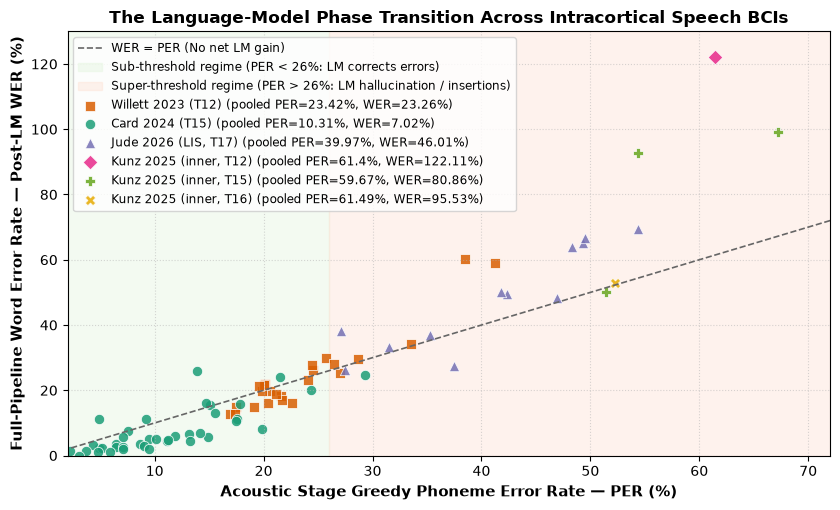

In [4]:
with open(REPO_ROOT / "figures/results/20261124_repository_migration/session_per_vs_wer.json", encoding="utf-8") as f:
    phase_data = json.load(f)

fig, ax = plt.subplots(figsize=(8.5, 5.2))

palette = {
    "Card 2024 (T15)": ("#1b9e77", "o"),
    "Willett 2023 (T12)": ("#d95f02", "s"),
    "Jude 2026 (LIS, T17)": ("#7570b3", "^"),
    "Kunz 2025 (inner, T12)": ("#e7298a", "D"),
    "Kunz 2025 (inner, T15)": ("#66a61e", "P"),
    "Kunz 2025 (inner, T16)": ("#e6ab02", "X"),
}

x_grid = np.linspace(0, 80, 200)
ax.plot(x_grid, x_grid, ls="--", color="#666666", lw=1.2, label="WER = PER (No net LM gain)")
ax.axvspan(0, 26, color="#e5f5e0", alpha=0.45, label="Sub-threshold regime (PER < 26%: LM corrects errors)")
ax.axvspan(26, 75, color="#fee0d2", alpha=0.40, label="Super-threshold regime (PER > 26%: LM hallucination / insertions)")

for study_name, content in phase_data.items():
    color, marker = palette.get(study_name, ("#333333", "o"))
    pers = [s["per"] for s in content["sessions"]]
    wers = [s["wer"] for s in content["sessions"]]
    ax.scatter(
        pers, wers, c=color, marker=marker, s=55, alpha=0.85, edgecolors="white", linewidth=0.6,
        label=f"{study_name} (pooled PER={content['pooled']['per']}%, WER={content['pooled']['wer']}%)"
    )

ax.set_xlim(2, 72)
ax.set_ylim(0, 130)
ax.set_xlabel("Acoustic Stage Greedy Phoneme Error Rate — PER (%)", fontsize=11, fontweight="bold")
ax.set_ylabel("Full-Pipeline Word Error Rate — Post-LM WER (%)", fontsize=11, fontweight="bold")
ax.set_title("The Language-Model Phase Transition Across Intracortical Speech BCIs", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()

Two distinct regimes emerge clearly from the phase diagram:
* **Sub-threshold error-correction regime ($\text{PER} < 26\%$, green zone)**: Every session from Card 2024 (T15) and Willett 2023 (T12) lies below the diagonal ($\text{WER} < \text{PER}$). On T15, a $10.19\%$ greedy PER is compressed down to $7.02\%$ single-model WER ($6.25\%$ with BiGRU).
* **Super-threshold hallucination regime ($\text{PER} > 30\%$, red zone)**: When phoneme posteriors are too corrupted (as in Jude 2026b T17 severe anarthria/LIS conversational sessions or Kunz 2025 inner-speech from-scratch training on 1–3 sparse sessions), WFST beam search splits corrupted phoneme spans into multiple short words to satisfy lexicon constraints, inflating word insertions so that $\text{WER} > \text{PER}$.

---

## 4. 403-Day Neural Drift vs. Unsupervised CORP Recalibration (Fan et al., *NeurIPS* 2023)

Intracortical Utah arrays experience day-to-day recording turnover (micromotion, gliosis, unit dropout). If a decoder trained on Day 0 is kept frozen, accuracy degrades severely over months.
**Fan et al. (*NeurIPS* 2023)** introduced **CORP**, which uses language-model-corrected outputs as unsupervised pseudo-labels to recalibrate both the day-specific input layer and the shared RNN backbone. Let's load `studies/20231201_fan/results/` and plot the 10 follow-up sessions across 403 days:

Day-0 Seed CER: 2.65% | Frozen Static 403-day CER: 50.85% | CORP v6 Adapted CER: 6.20%


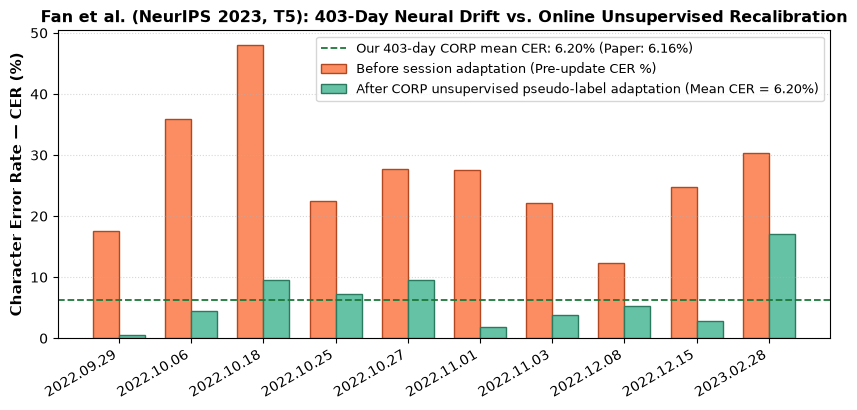

In [5]:
fan_dir = REPO_ROOT / "studies/20231201_fan/results/20261124_import_corp_archive"
with open(fan_dir / "tier2_seed_model_inference.json", encoding="utf-8") as f:
    tier2_frozen = json.load(f)
with open(fan_dir / "tier3_corp_sim_v6.json", encoding="utf-8") as f:
    tier3_corp = json.load(f)

sessions = [s["session"] for s in tier3_corp["sessions"]]
pre_cer = [s["pre"] for s in tier3_corp["sessions"]]
corp_post_cer = [s["post"] for s in tier3_corp["sessions"]]

mean_post = tier3_corp["summary"]["mean_post"]
static_ref = tier3_corp["summary"]["static_ref"]
seed_cer = tier2_frozen["seed_selftest"]["pooled_cer_pct"]
print(f"Day-0 Seed CER: {seed_cer:.2f}% | Frozen Static 403-day CER: {static_ref:.2f}% | CORP v6 Adapted CER: {mean_post:.2f}%")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(sessions))
width = 0.36

ax.bar(x - width/2, pre_cer, width, color="#fc8d62", edgecolor="#b34820",
       label="Before session adaptation (Pre-update CER %)")
ax.bar(x + width/2, corp_post_cer, width, color="#66c2a5", edgecolor="#2b7a5f",
       label=f"After CORP unsupervised pseudo-label adaptation (Mean CER = {mean_post:.2f}%)")

ax.axhline(mean_post, color="#1b7837", ls="--", lw=1.3,
           label=f"Our 403-day CORP mean CER: {mean_post:.2f}% (Paper: 6.16%)")
ax.set_xticks(x)
ax.set_xticklabels([s.replace("t5.", "") for s in sessions], rotation=30, ha="right")
ax.set_ylabel("Character Error Rate — CER (%)", fontsize=10.5, fontweight="bold")
ax.set_title("Fan et al. (NeurIPS 2023, T5): 403-Day Neural Drift vs. Online Unsupervised Recalibration",
             fontsize=11.5, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Suggested Exercises (For Students & AI Agents)
1. **Compare OPT-6.7B vs. Qwen3-8B on Locked-In Syndrome Speech**: In Section 2, point `willett_dir` to `studies/20260428_jude/results/20261124_import_lis_decode/` and compare `off_5g_opt_official.tsv` against `off_5g_opt_qwen3base_fx.tsv`.
2. **Where to go next?**
   - Open [`02_memory_wall_autopsy_16gb_gpu.ipynb`](02_memory_wall_autopsy_16gb_gpu.ipynb) to benchmark why official pipelines require 300 GB RAM + 80 GB A100 and how `mmap` + BF16 single-layer cuDNN stacks fit comfortably inside 16 GB VRAM.
   - Open [`03_single_session_end_to_end_demo.ipynb`](03_single_session_end_to_end_demo.ipynb) to train a production `InputNet + TypingGRU` neural decoder from scratch in ~5 seconds on your GPU.